
# Corporate Distress Prediction & Credit Risk Classification

**Financial Machine Learning | Portfolio Project**

## 1. Data Loading & Exploration

This project examines two credit risk problems:

- **Bankruptcy prediction:** Can financial ratios help identify firms at risk of failure?
- **Credit rating classification:** How accurately can we distinguish investment-grade from speculative-grade companies?

I use two public datasets: Taiwanese Company Bankruptcy Prediction and Corporate Credit Rating.

The first step is to load both datasets, examine their structure, and understand the distribution of bankruptcy events.


In [17]:
# Imports and configuration
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

# Project paths
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

# Load datasets
csv_files = list(DATA_DIR.rglob("*.csv"))

bankruptcy_df = None
credit_df = None

for file in csv_files:
    data = pd.read_csv(file, low_memory=False)
    data.columns = data.columns.str.strip()

    if "Bankrupt?" in data.columns:
        bankruptcy_df = data

    elif "Rating" in data.columns:
        credit_df = data

if bankruptcy_df is None or credit_df is None:
    raise FileNotFoundError(
        "Both datasets must be available as CSV files in the data folder."
    )

# Dataset overview
summary = pd.DataFrame({
    "Dataset": ["Bankruptcy", "Credit Rating"],
    "Observations": [len(bankruptcy_df), len(credit_df)],
    "Features / Columns": [
        bankruptcy_df.shape[1],
        credit_df.shape[1]
    ],
    "Missing Values": [
        bankruptcy_df.isna().sum().sum(),
        credit_df.isna().sum().sum()
    ]
})

display(summary)

# Bankruptcy class distribution
bankruptcy_counts = bankruptcy_df["Bankrupt?"].value_counts().sort_index()

display(
    pd.DataFrame({
        "Class": ["Healthy", "Bankrupt"],
        "Count": bankruptcy_counts.reindex([0, 1]).values,
        "Percentage": (
            bankruptcy_counts.reindex([0, 1]).values
            / len(bankruptcy_df) * 100
        ).round(2)
    })
)

display(bankruptcy_df.head())
display(credit_df.head())

,Dataset,Observations,Features / Columns,Missing Values
0,Bankruptcy,6819,96,0
1,Credit Rating,2029,31,0


,Class,Count,Percentage
0,Healthy,6599,96.77
1,Bankrupt,220,3.23


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


,Rating,Name,Symbol,Rating Agency Name,Date,Sector,currentRatio,quickRatio,cashRatio,daysOfSalesOutstanding,...,effectiveTaxRate,freeCashFlowOperatingCashFlowRatio,freeCashFlowPerShare,cashPerShare,companyEquityMultiplier,ebitPerRevenue,enterpriseValueMultiple,operatingCashFlowPerShare,operatingCashFlowSalesRatio,payablesTurnover
0,A,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,11/27/2015,Consumer Durables,0.945894,0.426395,0.099690,44.203245,...,0.202716,0.437551,6.810673,9.809403,4.008012,0.049351,7.057088,15.565438,0.058638,3.906655
1,BBB,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,2/13/2014,Consumer Durables,1.033559,0.498234,0.203120,38.991156,...,0.074155,0.541997,8.625473,17.402270,3.156783,0.048857,6.460618,15.914250,0.067239,4.002846
2,BBB,Whirlpool Corporation,WHR,Fitch Ratings,3/6/2015,Consumer Durables,0.963703,0.451505,0.122099,50.841385,...,0.214529,0.513185,9.693487,13.103448,4.094575,0.044334,10.491970,18.888889,0.074426,3.483510
3,BBB,Whirlpool Corporation,WHR,Fitch Ratings,6/15/2012,Consumer Durables,1.019851,0.510402,0.176116,41.161738,...,1.816667,-0.147170,-1.015625,14.440104,3.630950,-0.012858,4.080741,6.901042,0.028394,4.581150
4,BBB,Whirlpool Corporation,WHR,Standard & Poor's Ratings Services,10/24/2016,Consumer Durables,0.957844,0.495432,0.141608,47.761126,...,0.166966,0.451372,7.135348,14.257556,4.012780,0.053770,8.293505,15.808147,0.058065,3.857790



## 2. Data Preparation & Baseline Model

Before training a predictive model, I clean the bankruptcy dataset and examine the class imbalance.

I remove constant features, separate the financial ratios from the target variable, and use a stratified 80/20 train-test split.

To establish a baseline, I train a Dummy Classifier that always predicts the majority class.

**Key question:** Can a model achieve high accuracy without identifying any bankrupt companies?


Missing values: 0
Removed constant columns: ['Net Income Flag']


,Sample,Total,Healthy,Bankrupt,Bankruptcy Rate (%)
0,Full dataset,6819,6599,220,3.23
1,Train,5455,5279,176,3.23
2,Test,1364,1320,44,3.23


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy Classifier,0.9677,0.0,0.0,0.0,0.5,0.0323


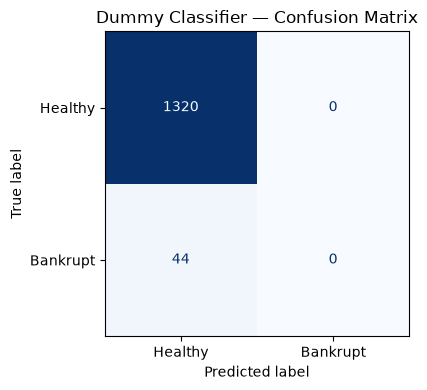

In [18]:
# Clean column names and remove constant features
df = bankruptcy_df.copy()
df.columns = df.columns.str.strip()

missing_count = df.isna().sum().sum()
constant_columns = df.columns[df.nunique(dropna=False) == 1].tolist()

if "Bankrupt?" in constant_columns:
    raise ValueError("The target column cannot be constant.")

df = df.drop(columns=constant_columns)

print("Missing values:", missing_count)
print("Removed constant columns:", constant_columns)

# Features and target
X = df.drop(columns="Bankrupt?")
y = df["Bankrupt?"].astype(int)

if X.isna().any().any():
    raise ValueError("Missing feature values require preprocessing.")

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "Sample": ["Full dataset", "Train", "Test"],
    "Total": [len(y), len(y_train), len(y_test)],
    "Healthy": [
        (y == 0).sum(),
        (y_train == 0).sum(),
        (y_test == 0).sum()
    ],
    "Bankrupt": [
        (y == 1).sum(),
        (y_train == 1).sum(),
        (y_test == 1).sum()
    ]
})

split_summary["Bankruptcy Rate (%)"] = (
    100 * split_summary["Bankrupt"] / split_summary["Total"]
)

display(split_summary.round(2))

# Dummy classifier: predict the majority class
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

y_dummy_pred = dummy_model.predict(X_test)
y_dummy_scores = dummy_model.predict_proba(X_test)[:, 1]

baseline_results = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y_test, y_dummy_pred),
    "Precision": precision_score(
        y_test, y_dummy_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_dummy_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_dummy_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_dummy_scores),
    "PR-AUC": average_precision_score(y_test, y_dummy_scores)
}

display(pd.DataFrame([baseline_results]).round(4))

# Confusion matrix
dummy_cm = confusion_matrix(y_test, y_dummy_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    dummy_cm,
    display_labels=["Healthy", "Bankrupt"]
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Dummy Classifier — Confusion Matrix")
plt.tight_layout()
plt.show()


## 3. Logistic Regression & Confusion Matrix

I start with Logistic Regression as the first predictive model for corporate bankruptcy.

To evaluate it, I use stratified 5-fold cross-validation and `cross_val_predict()` to generate out-of-fold predictions.

Rather than focusing only on accuracy, I examine the confusion matrix to understand two important errors:

- **False Positive:** A healthy company is flagged as bankrupt, creating unnecessary investigation costs.
- **False Negative:** A bankrupt company is classified as healthy, leaving a potential credit risk undetected.

**Key question:** Can Logistic Regression detect bankrupt firms more effectively than the majority-class baseline?


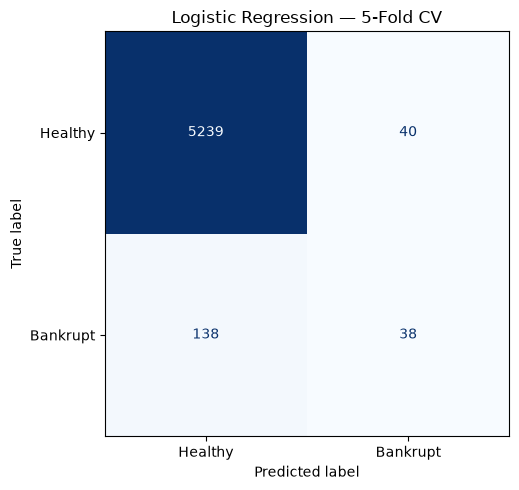

,Accuracy,Precision,Recall,F1
0,0.9674,0.4872,0.2159,0.2992


,Outcome,Number of Firms,Meaning
0,TN,5239,Healthy firms correctly identified
1,FP,40,Healthy firms incorrectly flagged
2,FN,138,Bankrupt firms missed by the model
3,TP,38,Bankrupt firms correctly identified


Detected bankruptcies: 38 out of 176 (21.6%)
False bankruptcy alerts: 40


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](94,)","['ROA(C) before interest and depreciation before interest', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax',..., 'Degree of Financial Leverage (DFL)', 'Interest Coverage Ratio (Interest expense to EBIT)', 'Equity to Liability']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,94
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [19]:

# Logistic Regression with preprocessing and cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

# Each observation is predicted out of fold
y_train_pred = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=-1
)

# Confusion matrix
logistic_cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = logistic_cm.ravel()

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=logistic_cm,
    display_labels=["Healthy", "Bankrupt"]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title("Logistic Regression — 5-Fold CV")
plt.tight_layout()
plt.show()

# Model performance
logistic_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_train, y_train_pred),
    "Precision": precision_score(
        y_train, y_train_pred, zero_division=0
    ),
    "Recall": recall_score(y_train, y_train_pred),
    "F1": f1_score(y_train, y_train_pred)
}])

display(logistic_results.round(4))

# Financial interpretation of classification errors
error_summary = pd.DataFrame({
    "Outcome": ["TN", "FP", "FN", "TP"],
    "Number of Firms": [tn, fp, fn, tp],
    "Meaning": [
        "Healthy firms correctly identified",
        "Healthy firms incorrectly flagged",
        "Bankrupt firms missed by the model",
        "Bankrupt firms correctly identified"
    ]
})

display(error_summary)

print(
    f"Detected bankruptcies: {tp} out of {tp + fn} "
    f"({100 * tp / (tp + fn):.1f}%)"
)

print(f"False bankruptcy alerts: {fp}")

# Fit the same pipeline on all training observations
logistic_model.fit(X_train, y_train)



### Findings

I evaluated Logistic Regression using stratified 5-fold cross-validation, with StandardScaler included in the pipeline.

The model achieved the following results:

| Metric | Result |
|---|---:|
| Accuracy | 96.74% |
| Precision | 48.72% |
| Recall | 21.59% |
| F1 Score | 0.2992 |

The model correctly identified **38 out of 176 bankrupt firms**, but missed 138 bankruptcies and generated 40 false alarms.

Although accuracy was high, recall remained low. This means the model classified most healthy firms correctly but failed to detect many actual bankruptcies.

**Takeaway:** Logistic Regression provides a useful baseline, but its default threshold is not suitable for detecting most corporate failures. In the next step, I adjust the decision threshold to improve recall.



## 4. Finding the Right Decision Threshold

Logistic Regression uses a default decision threshold of zero when working with `decision_function()` scores. However, this threshold may not be appropriate when only 3.23% of firms go bankrupt.

For Meridian Bank, missing a bankrupt company can be more costly than investigating a false alarm.

I examine how changing the decision threshold affects precision, recall, and the number of firms flagged for further investigation.

My objective is to identify **at least 70% of bankrupt firms** while keeping false alarms manageable.

**Key question:** How much precision must we sacrifice to detect 70% of corporate failures?


,Threshold,Precision,Recall,F1,Flagged Firms
0,Default (0),0.487,0.216,0.299,78
1,Selected (-2.599),0.231,0.705,0.348,537


,Target Recall,Achieved Recall,Precision,True Positives,False Positives,False Negatives,Flagged Firms
0,0.7,0.705,0.231,124,413,52,537


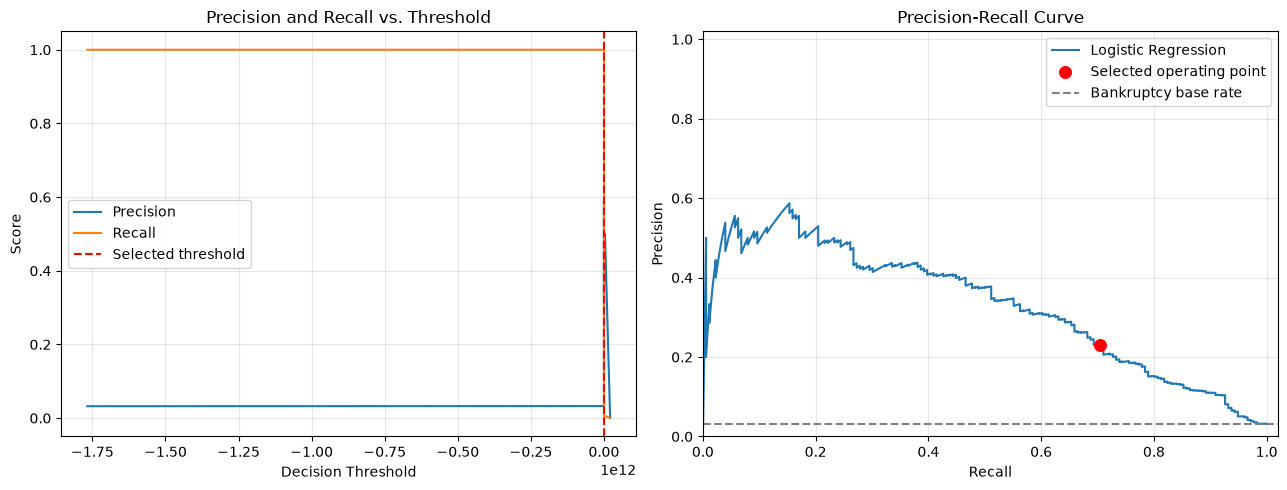

In [20]:

# Obtain out-of-fold decision scores
logistic_cv_scores = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=-1
)

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_train,
    logistic_cv_scores
)

target_recall = 0.70

# Find the highest threshold that achieves the recall target
eligible = np.where(recall[:-1] >= target_recall)[0]

if len(eligible) == 0:
    raise ValueError("The recall target cannot be achieved.")

selected_idx = eligible[-1]
optimal_threshold = float(thresholds[selected_idx])

# Compare default and selected thresholds
y_pred_default = (logistic_cv_scores >= 0).astype(int)
y_pred_selected = (
    logistic_cv_scores >= optimal_threshold
).astype(int)

def threshold_metrics(predictions, label):
    return {
        "Threshold": label,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Flagged Firms": int(predictions.sum())
    }

threshold_comparison = pd.DataFrame([
    threshold_metrics(y_pred_default, "Default (0)"),
    threshold_metrics(
        y_pred_selected,
        f"Selected ({optimal_threshold:.3f})"
    )
])

display(threshold_comparison.round(3))

# Financial impact of the selected threshold
tn, fp, fn, tp = confusion_matrix(
    y_train,
    y_pred_selected,
    labels=[0, 1]
).ravel()

operating_point = pd.DataFrame([{
    "Target Recall": target_recall,
    "Achieved Recall": recall_score(
        y_train, y_pred_selected
    ),
    "Precision": precision_score(
        y_train, y_pred_selected, zero_division=0
    ),
    "True Positives": tp,
    "False Positives": fp,
    "False Negatives": fn,
    "Flagged Firms": tp + fp
}])

display(operating_point.round(3))

# Visualize the threshold trade-off
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    thresholds,
    precision[:-1],
    label="Precision"
)
axes[0].plot(
    thresholds,
    recall[:-1],
    label="Recall"
)
axes[0].axvline(
    optimal_threshold,
    color="red",
    linestyle="--",
    label="Selected threshold"
)

axes[0].set(
    xlabel="Decision Threshold",
    ylabel="Score",
    title="Precision and Recall vs. Threshold"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    recall,
    precision,
    label="Logistic Regression"
)
axes[1].scatter(
    recall_score(y_train, y_pred_selected),
    precision_score(
        y_train, y_pred_selected, zero_division=0
    ),
    color="red",
    s=70,
    label="Selected operating point",
    zorder=3
)
axes[1].axhline(
    y_train.mean(),
    color="gray",
    linestyle="--",
    label="Bankruptcy base rate"
)

axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision-Recall Curve"
)
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Findings

I evaluated different decision thresholds using out-of-fold predictions from the Logistic Regression pipeline.

The objective was to detect at least 70% of bankrupt firms while limiting unnecessary credit investigations.

Lowering the decision threshold generally increases recall, but it can also lead to more false bankruptcy alerts.

I selected the highest threshold that achieved the target recall on the training cross-validation predictions.

**Takeaway:** The decision threshold should reflect the bank's risk tolerance and investigation capacity rather than relying only on the classifier's default setting.



## 5. ROC vs. Precision-Recall: Which Metric Matters More?

A model can distinguish bankrupt firms from healthy firms reasonably well while still generating many false bankruptcy alerts.

I compare two evaluation curves for Logistic Regression:

- **ROC Curve:** Measures how well the model separates bankrupt and healthy firms across decision thresholds.
- **Precision-Recall Curve:** Shows how reliably bankruptcy warnings identify actual failures as recall changes.

Since bankruptcy affects only about 3.23% of companies, the Precision-Recall curve is particularly important.

**Key question:** Does a high ROC-AUC mean that the model produces reliable bankruptcy alerts?


,Metric,Score
0,ROC-AUC,0.8973
1,Average Precision (AP),0.3326
2,Trapezoidal PR-AUC,0.3279


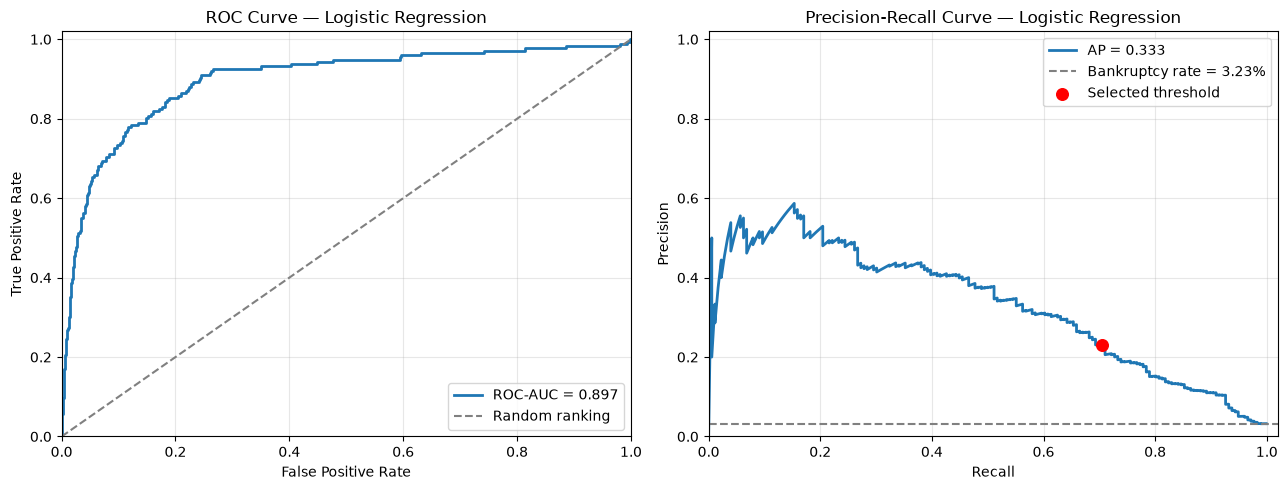

,ROC-AUC,Average Precision,Selected Threshold,Precision,Recall,True Positives,False Positives,False Negatives,Flagged Firms
0,0.8973,0.3326,-2.5991,0.2309,0.7045,124,413,52,537


In [21]:

# Evaluate Logistic Regression using out-of-fold scores
# The scores come from the scaled pipeline in Step 3.

y_scores = logistic_cv_scores

# ROC curve and ROC-AUC
fpr, tpr, _ = roc_curve(y_train, y_scores)
logistic_roc_auc = roc_auc_score(y_train, y_scores)

# Precision-Recall curve and Average Precision
pr_precision, pr_recall, _ = precision_recall_curve(
    y_train, y_scores
)

logistic_pr_auc = average_precision_score(
    y_train, y_scores
)

# Trapezoidal PR-AUC is not identical to Average Precision
logistic_pr_auc_trapezoidal = auc(
    pr_recall, pr_precision
)

base_rate = y_train.mean()

# Summary of ranking performance
auc_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "Average Precision (AP)",
        "Trapezoidal PR-AUC"
    ],
    "Score": [
        logistic_roc_auc,
        logistic_pr_auc,
        logistic_pr_auc_trapezoidal
    ]
})

display(auc_results.round(4))

# Visualize both curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    fpr, tpr,
    linewidth=2,
    label=f"ROC-AUC = {logistic_roc_auc:.3f}"
)
axes[0].plot(
    [0, 1], [0, 1],
    "--", color="gray",
    label="Random ranking"
)

axes[0].set(
    title="ROC Curve — Logistic Regression",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    pr_recall, pr_precision,
    linewidth=2,
    label=f"AP = {logistic_pr_auc:.3f}"
)
axes[1].axhline(
    base_rate,
    linestyle="--",
    color="gray",
    label=f"Bankruptcy rate = {base_rate:.2%}"
)
axes[1].scatter(
    selected_recall := recall_score(y_train, y_pred_selected),
    selected_precision := precision_score(
        y_train, y_pred_selected, zero_division=0
    ),
    color="red",
    s=70,
    zorder=3,
    label="Selected threshold"
)

axes[1].set(
    title="Precision-Recall Curve — Logistic Regression",
    xlabel="Recall",
    ylabel="Precision"
)
axes[1].set_xlim(0, 1.02)
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Performance at the selected threshold from Step 4
tn, fp, fn, tp = confusion_matrix(
    y_train,
    y_pred_selected,
    labels=[0, 1]
).ravel()

evaluation_summary = pd.DataFrame([{
    "ROC-AUC": logistic_roc_auc,
    "Average Precision": logistic_pr_auc,
    "Selected Threshold": optimal_threshold,
    "Precision": selected_precision,
    "Recall": selected_recall,
    "True Positives": tp,
    "False Positives": fp,
    "False Negatives": fn,
    "Flagged Firms": tp + fp
}])

display(evaluation_summary.round(4))



### Findings

I evaluated the Logistic Regression model using out-of-fold decision scores from stratified 5-fold cross-validation.

ROC-AUC measures the model's ability to rank bankrupt firms above healthy firms, while Average Precision focuses on the quality of bankruptcy alerts across recall levels.

Because bankruptcies represent only about 3.23% of the dataset, a high ROC-AUC does not necessarily imply high precision.

The selected threshold from Step 4 illustrates the practical trade-off between detecting bankrupt firms and generating false alarms.

**Takeaway:** I use Average Precision, recall, and the confusion matrix alongside ROC-AUC to evaluate bankruptcy prediction performance.



## 6. Model Comparison & Final Bankruptcy Prediction

So far, I have evaluated Logistic Regression and examined how changing the decision threshold affects bankruptcy detection.

Now I compare four classifiers:

- Dummy Classifier
- Logistic Regression
- Random Forest
- Balanced Logistic Regression

I use stratified 5-fold cross-validation to compare their performance on the same training observations.

Because bankruptcy is rare, I focus on **Average Precision (PR-AUC)** rather than accuracy alone.

After selecting the strongest model, I choose a threshold targeting at least 70% recall and evaluate it on the held-out test set.

**Key question:** Which classifier provides the most useful bankruptcy warnings without generating an excessive number of false alarms?


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.9692,0.5870,0.1534,0.2432,0.9343,0.4095
1,Logistic Regression,0.9674,0.4872,0.2159,0.2992,0.8973,0.3326
2,Balanced Logistic,0.8715,0.1690,0.7614,0.2766,0.8858,0.3079
3,Dummy,0.9677,0.0000,0.0000,0.0000,0.5000,0.0323


,Model,Precision,Recall,F1,PR-AUC
1,Logistic Regression,0.4872,0.2159,0.2992,0.3326
2,Balanced Logistic,0.1690,0.7614,0.2766,0.3079


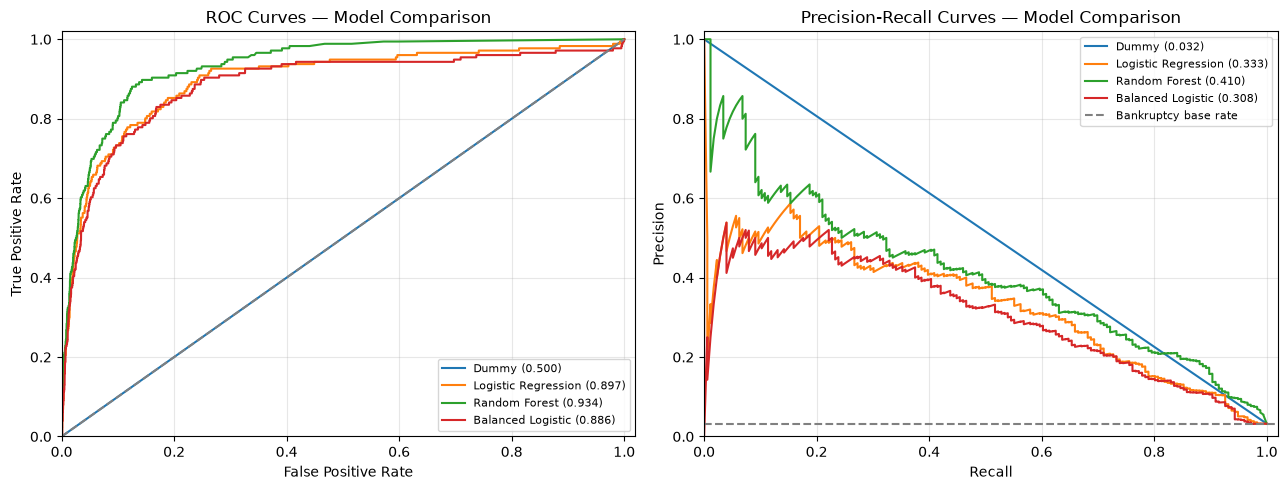

Selected model: Random Forest


,Selected Model,Threshold,CV Precision,CV Recall,CV Flagged Firms
0,Random Forest,0.131,0.2911,0.7045,426


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Random Forest,0.131,0.9377,0.3084,0.75,0.4371,0.9558,0.529,33,74,11,1246


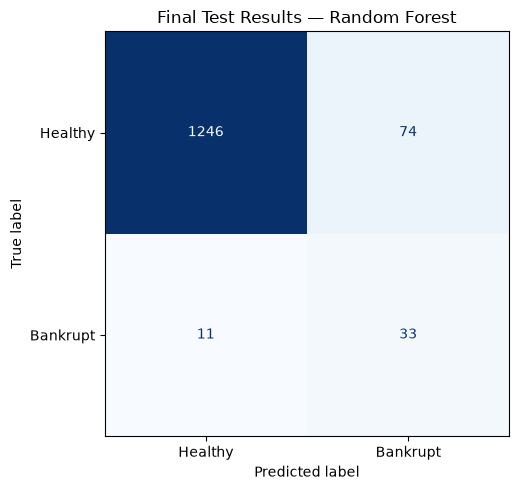

In [22]:

# Compare bankruptcy prediction models
models = {
    "Dummy": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Balanced Logistic": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

# Cross-validation on training data only
cv_results = []
model_scores = {}

for name, model in models.items():

    scores = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    model_scores[name] = scores

    # Default classification threshold
    predictions = (scores >= 0.5).astype(int)

    cv_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(y_train, predictions),
        "F1": f1_score(y_train, predictions),
        "ROC-AUC": roc_auc_score(y_train, scores),
        "PR-AUC": average_precision_score(y_train, scores)
    })

comparison_df = pd.DataFrame(cv_results).sort_values(
    "PR-AUC", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


# Compare ordinary and balanced Logistic Regression
weight_comparison = comparison_df[
    comparison_df["Model"].isin([
        "Logistic Regression",
        "Balanced Logistic"
    ])
][["Model", "Precision", "Recall", "F1", "PR-AUC"]]

display(weight_comparison.round(4))


# Visual comparison of model performance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, scores in model_scores.items():

    fpr, tpr, _ = roc_curve(y_train, scores)
    pr_precision, pr_recall, _ = precision_recall_curve(
        y_train, scores
    )

    model_roc_auc = roc_auc_score(y_train, scores)
    model_ap = average_precision_score(y_train, scores)

    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} ({model_roc_auc:.3f})"
    )

    axes[1].plot(
        pr_recall,
        pr_precision,
        label=f"{name} ({model_ap:.3f})"
    )

axes[0].plot(
    [0, 1], [0, 1],
    "--", color="gray"
)

axes[0].set(
    title="ROC Curves — Model Comparison",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)

axes[1].axhline(
    y_train.mean(),
    linestyle="--",
    color="gray",
    label="Bankruptcy base rate"
)

axes[1].set(
    title="Precision-Recall Curves — Model Comparison",
    xlabel="Recall",
    ylabel="Precision"
)

for ax in axes:
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Select the model with the highest CV Average Precision
candidates = comparison_df[
    comparison_df["Model"] != "Dummy"
]

best_model_name = candidates.iloc[0]["Model"]
best_model = clone(models[best_model_name])

print("Selected model:", best_model_name)


# Select threshold using training CV predictions
target_recall = 0.70

best_scores = model_scores[best_model_name]

pr_precision, pr_recall, thresholds = precision_recall_curve(
    y_train, best_scores
)

eligible = np.where(
    pr_recall[:-1] >= target_recall
)[0]

if len(eligible) == 0:
    raise ValueError("The recall target cannot be achieved.")

best_threshold = float(
    thresholds[eligible[-1]]
)

cv_selected_predictions = (
    best_scores >= best_threshold
).astype(int)

cv_precision = precision_score(
    y_train,
    cv_selected_predictions,
    zero_division=0
)

cv_recall = recall_score(
    y_train,
    cv_selected_predictions
)

display(pd.DataFrame([{
    "Selected Model": best_model_name,
    "Threshold": best_threshold,
    "CV Precision": cv_precision,
    "CV Recall": cv_recall,
    "CV Flagged Firms": int(cv_selected_predictions.sum())
}]).round(4))


# Fit on the full training set
best_model.fit(X_train, y_train)

# Final evaluation on held-out test data
test_scores = best_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_scores >= best_threshold
).astype(int)

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = test_cm.ravel()

final_results = pd.DataFrame([{
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(y_test, test_predictions),
    "F1": f1_score(y_test, test_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "PR-AUC": average_precision_score(y_test, test_scores),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}])

display(final_results.round(4))


# Final confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Healthy", "Bankrupt"]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(f"Final Test Results — {best_model_name}")

plt.tight_layout()
plt.show()


# Save the final model and results
joblib.dump(
    {
        "model": best_model,
        "threshold": best_threshold,
        "features": X_train.columns.tolist()
    },
    RESULTS_DIR / "bankruptcy_model.joblib"
)

comparison_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

final_results.to_csv(
    RESULTS_DIR / "bankruptcy_test_results.csv",
    index=False
)



### Findings

I compared four bankruptcy prediction models using stratified 5-fold cross-validation. Model selection was based on Average Precision (AP), which is particularly useful for imbalanced datasets.

**Random Forest** achieved the highest cross-validation Average Precision (0.4095), outperforming Logistic Regression (0.3326) and Balanced Logistic Regression (0.3079).

The balanced Logistic Regression improved recall to 76.14% at its default threshold, but precision decreased to 16.90%, demonstrating the trade-off between detecting bankruptcies and generating false alarms.

### Final Test Performance — Random Forest

| Metric | Result |
|---|---:|
| Accuracy | 93.77% |
| ROC-AUC | 0.9558 |
| Average Precision | 0.5290 |
| Precision | 30.84% |
| Recall | 75.00% |
| F1 Score | 0.4371 |
| Selected Threshold | 0.1310 |

At the selected threshold, the model correctly identified **33 out of 44 bankrupt companies** in the held-out test set.

However, it generated **74 false positives** and missed **11 actual bankruptcies**.

In total, the model flagged 107 companies for further investigation, of which 33 were genuinely bankrupt.

**Takeaway:** Random Forest provides useful bankruptcy risk signals, but its relatively low precision means that predictions should support credit analysts rather than replace their judgment.



## 7. Corporate Credit Rating Classification

Bankruptcy prediction tells us whether a company may fail, but credit ratings provide a broader view of financial risk.

In this section, I classify companies into three credit risk categories:

- **High Grade:** AAA, AA, A
- **Medium Grade:** BBB
- **Speculative:** BB and below

I use a Support Vector Classifier (SVC) with a One-vs-One strategy and a preprocessing pipeline for numerical and categorical features.

The most important distinction is the boundary between **Investment Grade (BBB and above)** and **Speculative Grade (BB and below)**.

**Key question:** How often does the model incorrectly classify a speculative-grade company as investment grade?


,Observations
Credit_Class,
High grade,494
Medium grade,671
Speculative,864


Training observations: 1610
Test observations: 419
Training companies: 474
Test companies: 119
Overlapping companies: 0


,Train,Test
Credit_Class,,
High grade,381,113
Medium grade,544,127
Speculative,685,179


,CV Accuracy,CV Macro F1,CV Weighted F1
0,0.4957,0.46,0.4881


,Accuracy,Macro F1,Weighted F1
0,0.5227,0.4973,0.5225


              precision    recall  f1-score   support

  High grade       0.49      0.35      0.41       113
Medium grade       0.37      0.46      0.41       127
 Speculative       0.68      0.68      0.68       179

    accuracy                           0.52       419
   macro avg       0.51      0.50      0.50       419
weighted avg       0.53      0.52      0.52       419



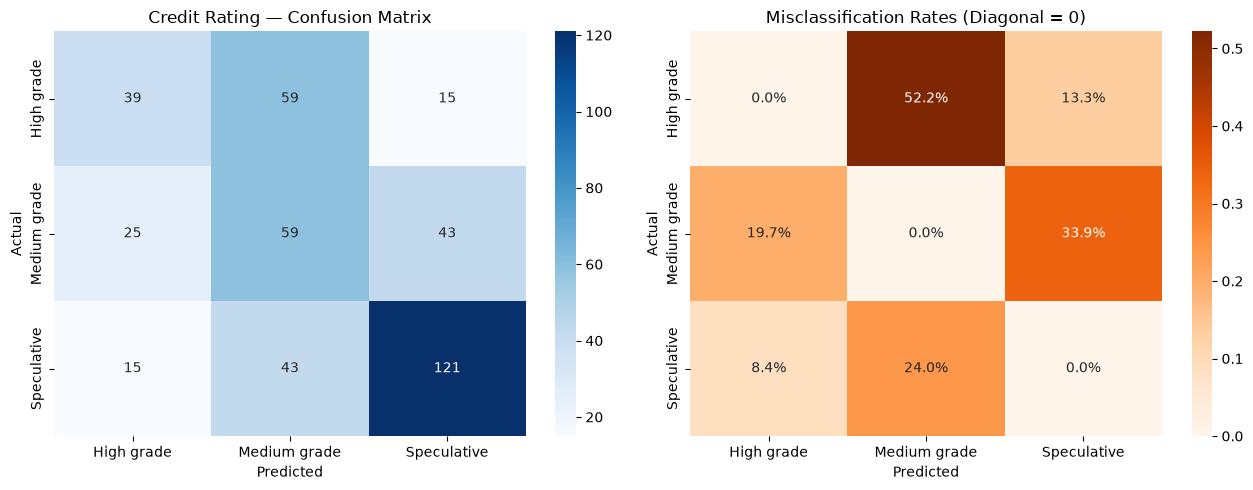

,Actual,Predicted,Count,Error Rate (%)
0,High grade,Medium grade,59,52.21
3,Medium grade,Speculative,43,33.86
5,Speculative,Medium grade,43,24.02
2,Medium grade,High grade,25,19.69
1,High grade,Speculative,15,13.27


,Dangerous Errors,Conservative Errors,Total Boundary Errors
0,58,58,116


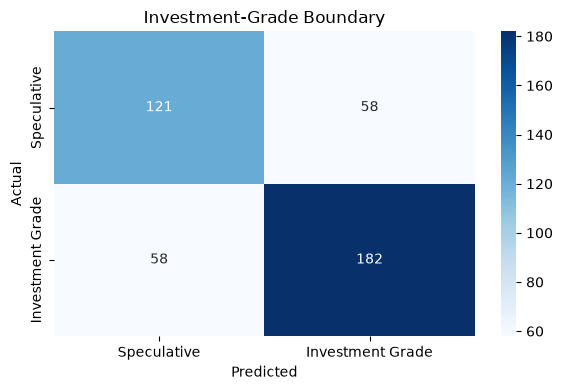

['d:\\suri\\Univercity\\project\\phytone\\results\\credit_rating_model.joblib']

In [23]:

# Prepare the credit rating dataset
df_credit = credit_df.copy()
df_credit.columns = df_credit.columns.str.strip()

rating_mapping = {
    "AAA": "High grade",
    "AA": "High grade",
    "A": "High grade",
    "BBB": "Medium grade",
    "BB": "Speculative",
    "B": "Speculative",
    "CCC": "Speculative",
    "CC": "Speculative",
    "C": "Speculative",
    "D": "Speculative"
}

CLASS_ORDER = ["High grade", "Medium grade", "Speculative"]

# Standardize credit ratings
df_credit["Standardized_Rating"] = (
    df_credit["Rating"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace("+", "", regex=False)
    .str.replace("-", "", regex=False)
)

df_credit["Credit_Class"] = (
    df_credit["Standardized_Rating"].map(rating_mapping)
)

if df_credit["Credit_Class"].isna().any():
    raise ValueError("Unrecognized credit rating found.")

display(
    df_credit["Credit_Class"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename("Observations")
    .to_frame()
)

# Identify companies for group-aware splitting
company_groups = df_credit["Symbol"].fillna(
    df_credit["Name"]
).astype(str).str.strip()

if company_groups.eq("").any():
    raise ValueError("Some company identifiers are missing.")

# Separate predictors and target
# Exclude identifiers, dates, rating labels and agency metadata
excluded_columns = [
    "Rating",
    "Standardized_Rating",
    "Credit_Class",
    "Name",
    "Symbol",
    "Date",
    "Rating Agency Name"
]

X_credit = df_credit.drop(
    columns=excluded_columns,
    errors="ignore"
)

y_credit = df_credit["Credit_Class"]

# Hold out entire companies for testing
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    group_split.split(
        X_credit,
        y_credit,
        groups=company_groups
    )
)

X_credit_train = X_credit.iloc[train_idx]
X_credit_test = X_credit.iloc[test_idx]

y_credit_train = y_credit.iloc[train_idx]
y_credit_test = y_credit.iloc[test_idx]

groups_train = company_groups.iloc[train_idx]
groups_test = company_groups.iloc[test_idx]

assert set(groups_train).isdisjoint(set(groups_test))

print("Training observations:", len(X_credit_train))
print("Test observations:", len(X_credit_test))
print("Training companies:", groups_train.nunique())
print("Test companies:", groups_test.nunique())
print("Overlapping companies:", 0)

split_distribution = pd.DataFrame({
    "Train": y_credit_train.value_counts(),
    "Test": y_credit_test.value_counts()
}).reindex(CLASS_ORDER, fill_value=0)

display(split_distribution)

# Check that all classes are represented
if (
    y_credit_train.nunique() != 3
    or y_credit_test.nunique() != 3
):
    raise ValueError(
        "All three classes must appear in train and test."
    )

# Build preprocessing pipelines
numerical_features = X_credit.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_credit.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = [
    ("numeric", numeric_pipeline, numerical_features)
]

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

credit_preprocessor = ColumnTransformer(transformers)

# Support Vector Classifier
credit_pipeline = Pipeline([
    ("preprocessor", credit_preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        decision_function_shape="ovo",
        random_state=RANDOM_STATE
    ))
])

# Group-aware cross-validation
credit_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

y_credit_cv_pred = cross_val_predict(
    credit_pipeline,
    X_credit_train,
    y_credit_train,
    groups=groups_train,
    cv=credit_cv,
    method="predict"
)

cv_summary = pd.DataFrame([{
    "CV Accuracy": accuracy_score(
        y_credit_train, y_credit_cv_pred
    ),
    "CV Macro F1": f1_score(
        y_credit_train,
        y_credit_cv_pred,
        average="macro"
    ),
    "CV Weighted F1": f1_score(
        y_credit_train,
        y_credit_cv_pred,
        average="weighted"
    )
}])

display(cv_summary.round(4))

# Final training and held-out test evaluation
credit_pipeline.fit(
    X_credit_train,
    y_credit_train
)

y_credit_pred = credit_pipeline.predict(
    X_credit_test
)

credit_results = pd.DataFrame([{
    "Accuracy": accuracy_score(
        y_credit_test, y_credit_pred
    ),
    "Macro F1": f1_score(
        y_credit_test, y_credit_pred, average="macro"
    ),
    "Weighted F1": f1_score(
        y_credit_test, y_credit_pred, average="weighted"
    )
}])

display(credit_results.round(4))

print(
    classification_report(
        y_credit_test,
        y_credit_pred,
        labels=CLASS_ORDER,
        zero_division=0
    )
)

# Confusion matrices
credit_cm = confusion_matrix(
    y_credit_test,
    y_credit_pred,
    labels=CLASS_ORDER
)

credit_cm_normalized = confusion_matrix(
    y_credit_test,
    y_credit_pred,
    labels=CLASS_ORDER,
    normalize="true"
)

error_matrix = credit_cm_normalized.copy()
np.fill_diagonal(error_matrix, 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    credit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    ax=axes[0]
)

axes[0].set(
    title="Credit Rating — Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual"
)

sns.heatmap(
    error_matrix,
    annot=True,
    fmt=".1%",
    cmap="Oranges",
    vmin=0,
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    ax=axes[1]
)

axes[1].set(
    title="Misclassification Rates (Diagonal = 0)",
    xlabel="Predicted",
    ylabel="Actual"
)

plt.tight_layout()
plt.show()

# Identify major classification errors
errors = []

for i, actual_class in enumerate(CLASS_ORDER):
    for j, predicted_class in enumerate(CLASS_ORDER):
        if i != j:
            errors.append({
                "Actual": actual_class,
                "Predicted": predicted_class,
                "Count": int(credit_cm[i, j]),
                "Error Rate (%)": (
                    100 * credit_cm_normalized[i, j]
                )
            })

error_summary = pd.DataFrame(errors).sort_values(
    "Count",
    ascending=False
)

display(error_summary.head(5).round(2))

# Analyze the investment-grade boundary
actual_classes = np.asarray(y_credit_test)
predicted_classes = np.asarray(y_credit_pred)

actual_ig = actual_classes != "Speculative"
predicted_ig = predicted_classes != "Speculative"

dangerous_errors = int(
    np.sum(~actual_ig & predicted_ig)
)

conservative_errors = int(
    np.sum(actual_ig & ~predicted_ig)
)

boundary_results = pd.DataFrame([{
    "Dangerous Errors": dangerous_errors,
    "Conservative Errors": conservative_errors,
    "Total Boundary Errors": (
        dangerous_errors + conservative_errors
    )
}])

display(boundary_results)

boundary_cm = confusion_matrix(
    actual_ig,
    predicted_ig,
    labels=[False, True]
)

fig, ax = plt.subplots(figsize=(6, 4))

sns.heatmap(
    boundary_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Speculative",
        "Investment Grade"
    ],
    yticklabels=[
        "Speculative",
        "Investment Grade"
    ],
    ax=ax
)

ax.set(
    title="Investment-Grade Boundary",
    xlabel="Predicted",
    ylabel="Actual"
)

plt.tight_layout()
plt.show()

# Save final results
credit_results.to_csv(
    RESULTS_DIR / "credit_rating_results.csv",
    index=False
)

boundary_results.to_csv(
    RESULTS_DIR / "credit_boundary_errors.csv",
    index=False
)

joblib.dump(
    credit_pipeline,
    RESULTS_DIR / "credit_rating_model.joblib"
)



### Findings

I evaluated the SVC model using a group-aware train-test split and Stratified Group 5-Fold Cross-Validation to prevent the same company from appearing in both training and testing.

### Classification Performance

| Metric | Result |
|---|---:|
| Accuracy | 52.27% |
| Macro F1 | 0.4973 |
| Weighted F1 | 0.5225 |

The model achieved moderate classification performance when evaluated on companies not included in the training set.

### Investment-Grade Boundary Errors

| Error Type | Count |
|---|---:|
| Speculative → Investment Grade | 58 |
| Investment Grade → Speculative | 58 |
| Total Boundary Errors | 116 |

The 58 dangerous errors represent speculative-grade companies incorrectly classified as investment grade, potentially exposing investors to greater credit risk.

The 58 conservative errors represent investment-grade companies incorrectly classified as speculative, potentially causing missed investment opportunities.

The group-aware evaluation produced lower accuracy than the previous random split (57.64%), suggesting that the earlier evaluation may have benefited from repeated company observations across training and testing.

**Takeaway:** The SVC model captures some credit rating patterns, but its classification errors, particularly around the investment-grade boundary, make it unsuitable for fully automated credit decisions without further improvement and human oversight.



## 8. Practical Application: Which 50 Firms Should We Investigate?

A credit risk model becomes more useful when its predictions support real business decisions.

Suppose Meridian Bank has enough resources to investigate only 50 companies. Rather than reviewing every company flagged by the model, I rank firms by their predicted bankruptcy probabilities and focus on the 50 highest-risk observations.

To evaluate this strategy, I use:

- **Precision@50:** How many of the 50 selected companies actually went bankrupt?
- **Recall@50:** What proportion of all bankrupt companies did we identify?
- **Lift@50:** How much better is the selection than choosing companies randomly?

**Key question:** Can machine learning help the bank allocate its limited credit investigation resources more effectively?


,Investigation Capacity,Bankrupt Firms Detected,Precision@50,Recall@50,Random Selection Precision,Lift@50
0,50,25,0.5,0.5682,0.0323,15.5


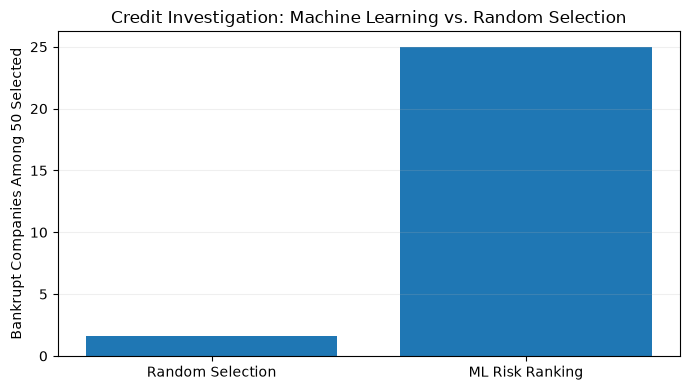

,Risk_Rank,Firm_ID,Bankruptcy_Probability,Actual_Bankruptcy
0,1,2640,0.7112,1
1,2,427,0.6387,1
2,3,1870,0.5956,1
3,4,2004,0.5877,1
4,5,2470,0.5854,1
5,6,1640,0.5792,1
6,7,3540,0.5771,0
7,8,54,0.5668,1
8,9,1568,0.5603,0
9,10,1035,0.5503,0


In [24]:

# Prioritize companies using the final bankruptcy model
# This is an additional analysis of the held-out test predictions.

investigation_capacity = 50

if not hasattr(best_model, "predict_proba"):
    raise ValueError(
        "The selected model must provide bankruptcy probabilities."
    )

# Predicted bankruptcy probabilities for the test set
bankruptcy_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create a ranking table
risk_ranking = pd.DataFrame({
    "Firm_ID": X_test.index.to_numpy(),
    "Bankruptcy_Probability": bankruptcy_probabilities,
    "Actual_Bankruptcy": np.asarray(y_test)
})

risk_ranking = risk_ranking.sort_values(
    "Bankruptcy_Probability",
    ascending=False
).reset_index(drop=True)

risk_ranking["Risk_Rank"] = np.arange(1, len(risk_ranking) + 1)

# Select the 50 firms with the highest predicted risk
top_50 = risk_ranking.head(investigation_capacity).copy()

# Evaluate the selected firms
detected_bankruptcies = int(top_50["Actual_Bankruptcy"].sum())
total_bankruptcies = int(y_test.sum())

precision_at_50 = detected_bankruptcies / investigation_capacity
recall_at_50 = detected_bankruptcies / total_bankruptcies

# Expected precision from random selection
random_precision = total_bankruptcies / len(y_test)

lift_at_50 = (
    precision_at_50 / random_precision
    if random_precision > 0 else np.nan
)

# Summary
top_50_results = pd.DataFrame([{
    "Investigation Capacity": investigation_capacity,
    "Bankrupt Firms Detected": detected_bankruptcies,
    "Precision@50": precision_at_50,
    "Recall@50": recall_at_50,
    "Random Selection Precision": random_precision,
    "Lift@50": lift_at_50
}])

display(top_50_results.round(4))

# Compare the model with random selection
comparison = pd.DataFrame({
    "Strategy": ["Random Selection", "ML Risk Ranking"],
    "Expected / Actual Bankruptcies": [
        investigation_capacity * random_precision,
        detected_bankruptcies
    ]
})

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    comparison["Strategy"],
    comparison["Expected / Actual Bankruptcies"]
)

ax.set(
    title="Credit Investigation: Machine Learning vs. Random Selection",
    ylabel="Bankrupt Companies Among 50 Selected"
)

ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Display the highest-risk observations
display(
    top_50[
        [
            "Risk_Rank",
            "Firm_ID",
            "Bankruptcy_Probability",
            "Actual_Bankruptcy"
        ]
    ].head(10).round(4)
)

# Save the ranking and summary
top_50.to_csv(
    RESULTS_DIR / "top_50_risk_ranking.csv",
    index=False
)

top_50_results.to_csv(
    RESULTS_DIR / "top_50_analysis.csv",
    index=False
)



### Findings

I evaluated a practical credit risk strategy by selecting the 50 companies with the highest predicted bankruptcy probabilities from the held-out test set.

### Top 50 Risk Analysis

| Metric | Result |
|---|---:|
| Investigation Capacity | 50 firms |
| Bankrupt Firms Detected | 25 |
| Precision@50 | 50.00% |
| Recall@50 | 56.82% |
| Lift@50 | 15.5x |

The model identified **25 of the 44 bankrupt companies** by prioritizing just 50 firms out of 1,364 test observations.

In comparison, randomly selecting 50 firms would identify approximately 1.61 bankrupt companies on average.

This means the model's risk-based ranking was approximately **15.5 times more effective than random selection** in this historical test sample.

### Business Implication

For a bank with limited investigation resources, ranking companies by predicted bankruptcy risk can help analysts focus on the most relevant cases.

However, these results are based on historical test data and do not guarantee the same performance in future credit decisions.

**Takeaway:** Machine learning can improve how banks prioritize credit investigations, even when they cannot review every potentially distressed company.



## 9. Conclusion & Limitations

This project explored two applications of machine learning in financial risk management: corporate bankruptcy prediction and credit rating classification.

### Key Findings

**1. Bankruptcy Prediction**

Random Forest achieved a ROC-AUC of 0.9558 and an Average Precision of 0.5290 on the held-out test set.

At the selected threshold, the model identified 33 out of 44 bankrupt firms, achieving 75% recall. However, it also generated 74 false alarms.

**2. Credit Rating Classification**

The SVC model achieved 52.27% accuracy using company-level group-aware splitting.

The model made 116 errors across the investment-grade boundary, including 58 cases where speculative-grade companies were incorrectly classified as investment grade.

**3. Practical Credit Risk Application**

By prioritizing the 50 companies with the highest predicted bankruptcy risk, the model identified 25 actual bankruptcies.

This represents 50% Precision@50, 56.82% Recall@50, and approximately 15.5 times the expected detection rate of random selection.

### Limitations

- **Class imbalance:** Bankruptcy events are rare, making precision and recall particularly important.
- **False alarms:** The bankruptcy model generates a substantial number of false positives, increasing the workload of credit analysts.
- **Historical data:** Performance on historical observations does not guarantee similar results in future market conditions.
- **Validation strategy:** Company-level splitting reduces overlap between training and testing in the credit rating analysis, but a fully time-based evaluation is still needed.
- **Generalizability:** Both models should be evaluated on additional companies, periods, and economic environments before practical deployment.

### Final Takeaway

Machine learning can support credit risk assessment by identifying potentially distressed companies and helping analysts prioritize investigations.

However, predictive accuracy alone is not sufficient. The financial consequences of false positives, false negatives, and credit rating misclassifications must also be considered.

**These models are best viewed as decision-support tools rather than replacements for professional financial judgment.**
